1. Importing libraries

In [455]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  
import os


2. Loading dataset using kagglehub

In [456]:
import kagglehub
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")
df = pd.read_csv(os.path.join(path,"healthcare-dataset-stroke-data.csv"))

df.head()



,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


3. Dataset overview

Tells about the size of dataset. (rows, columns)

In [457]:
df.shape

(5110, 12)

In [458]:
# show column, missing data and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


In [459]:
# numeric summary
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [460]:
# categorical summary
df.describe(include="string")

,gender,ever_married,work_type,Residence_type,smoking_status
count,5110,5110,5110,5110,5110
unique,3,2,5,2,4
top,Female,Yes,Private,Urban,never smoked
freq,2994,3353,2925,2596,1892


4. Understanding each column

In [461]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')

5. Dataset quality assessment

In [462]:
df.isnull().sum().sort_values(ascending=True)

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
smoking_status         0
stroke                 0
bmi                  201
dtype: int64

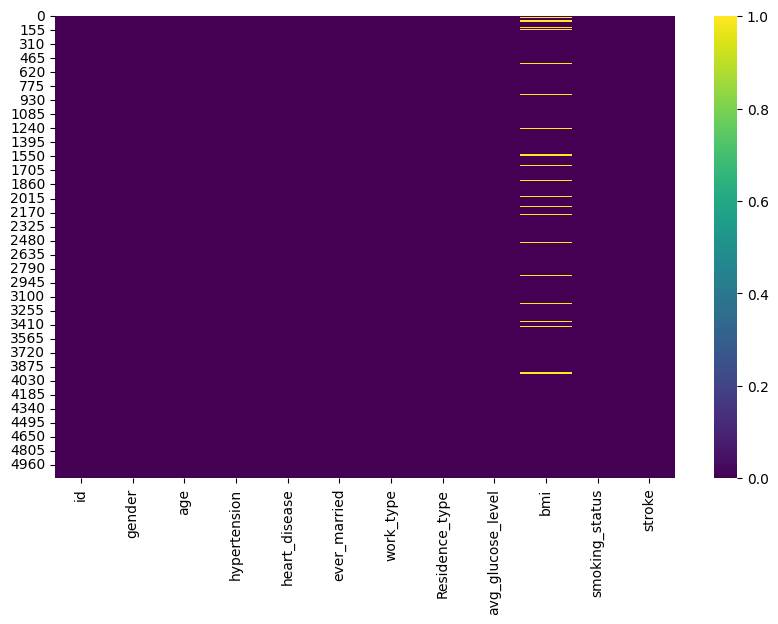

In [463]:
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cmap = 'viridis')
plt.show()

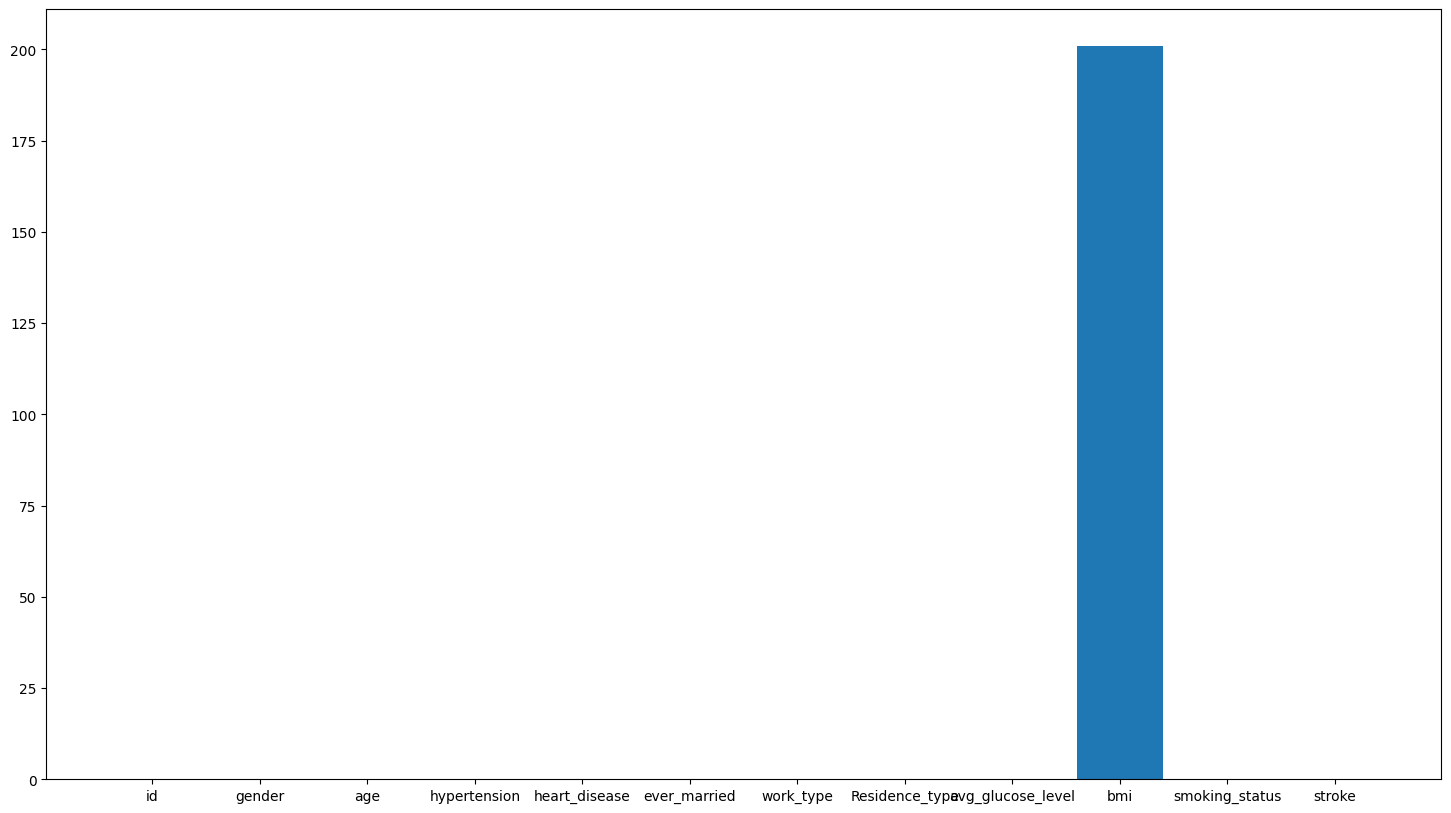

In [464]:
plt.figure(figsize=(18,10))
plt.bar(df.columns, df.isnull().sum())
plt.show()

In [465]:
# Check how many duplicated rows are in the data
df.duplicated().sum()

np.int64(0)

In [466]:
# Tell us  how many unique values are present in the data in each category
df.nunique()

id                   5110
gender                  3
age                   104
hypertension            2
heart_disease           2
ever_married            2
work_type               5
Residence_type          2
avg_glucose_level    3979
bmi                   418
smoking_status          4
stroke                  2
dtype: int64

Univariate analysis

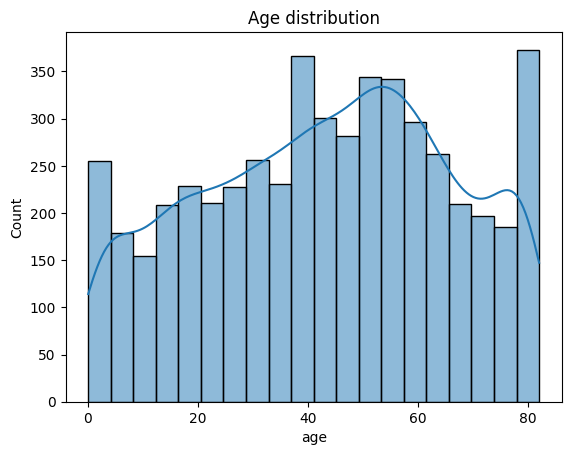

In [467]:
#Age
sns.histplot(df["age"],kde=True)
plt.title("Age distribution")
plt.show()

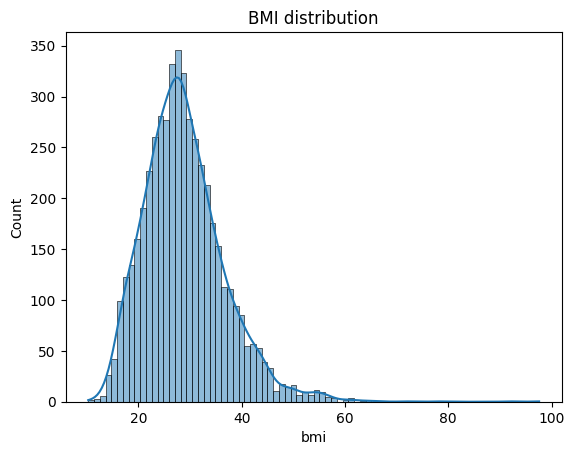

In [468]:
# Bmi
sns.histplot(df["bmi"], kde=True)
plt.title("BMI distribution")
plt.show()

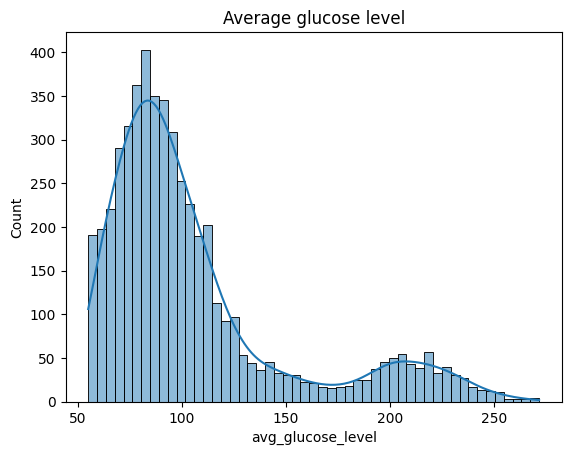

In [469]:
#average glucose level
sns.histplot(df["avg_glucose_level"], kde=True)
plt.title("Average glucose level")
plt.show()

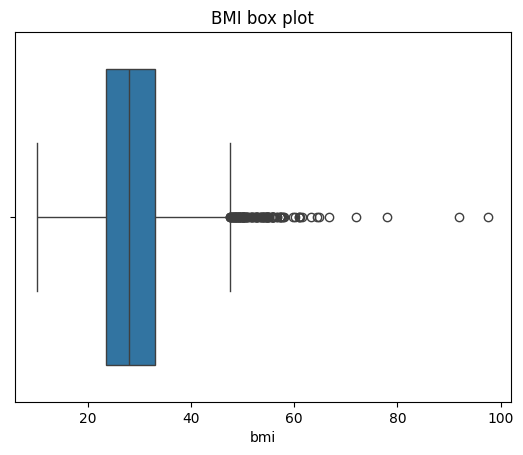

In [470]:
sns.boxplot(df["bmi"].dropna(), orient="h")
plt.title("BMI box plot")
plt.show()

Categorical features

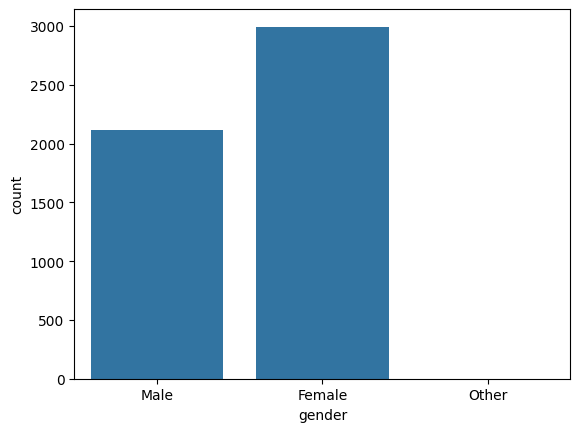

In [471]:
sns.countplot(data=df, x="gender")
plt.show()

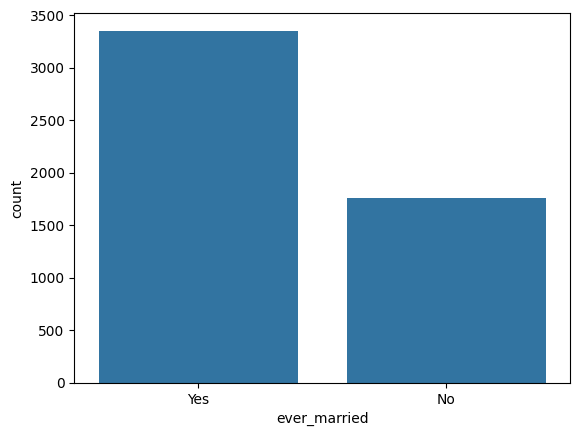

In [472]:
sns.countplot(data=df, x="ever_married")
plt.show()

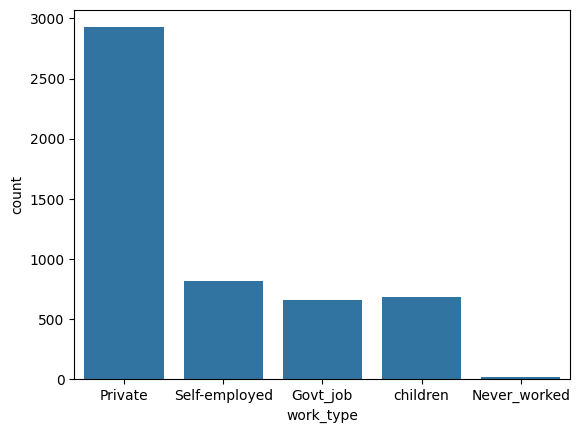

In [473]:
sns.countplot(data=df, x="work_type")
plt.show()

Bivariate analysis

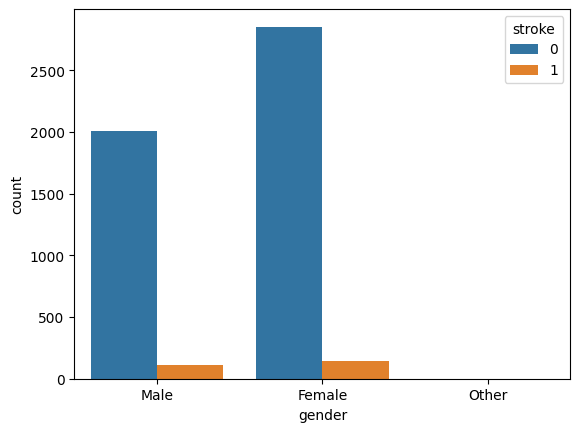

In [474]:
# Gender vs Stroke
sns.countplot(data = df, x="gender", hue="stroke")
plt.show()

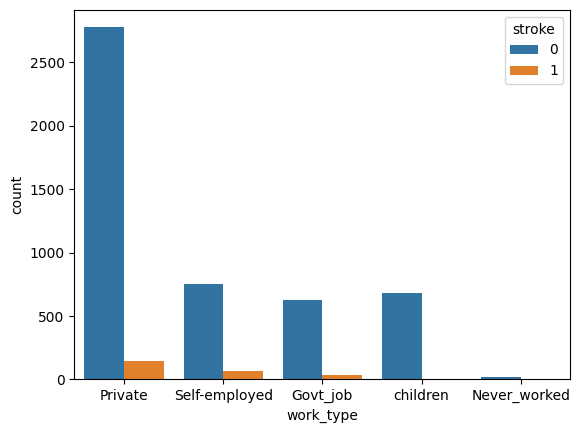

In [475]:
# Work_type vs Stroke
sns.countplot(data = df, x="work_type", hue="stroke")
plt.show()

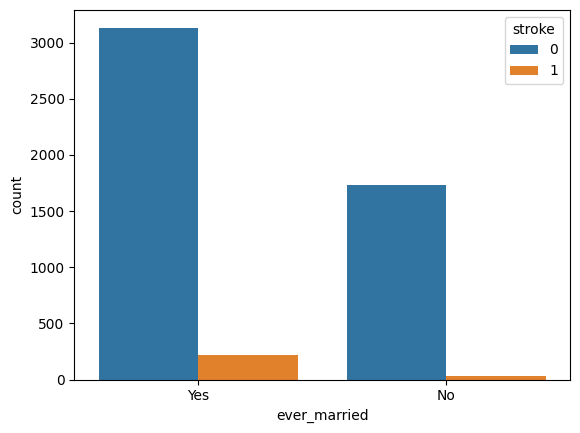

In [476]:
# ever_married vs Stroke
sns.countplot(data = df, x="ever_married", hue="stroke")
plt.show()

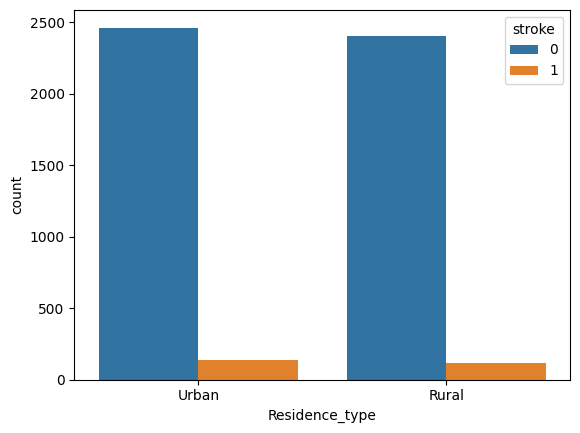

In [477]:
# Residence_type vs Stroke
sns.countplot(data = df, x="Residence_type", hue="stroke")
plt.show()

In [478]:
# age
# converting continuous data into discrete by creating bins

In [479]:
bins = [0, 12, 19, 39, 59, 100]
labels = ["Child", "Teen", "Adult", "Middle-aged", "Senior"]

df["Age_bin"] = pd.cut(df["age"], bins=bins, labels=labels)

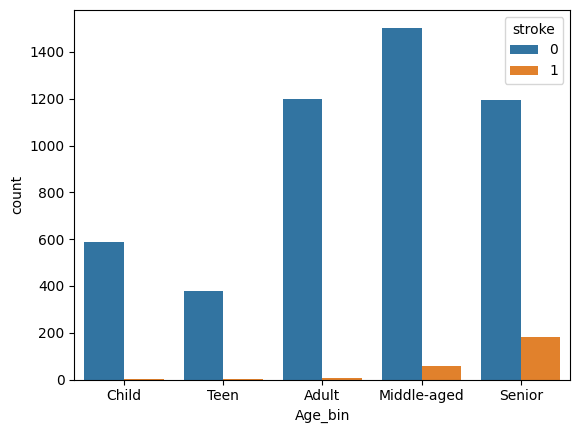

In [480]:
sns.countplot(data = df, x= "Age_bin", hue="stroke")
plt.show()

Age vs stroke shows that the senior and middle aged people experience more stroke than other category.

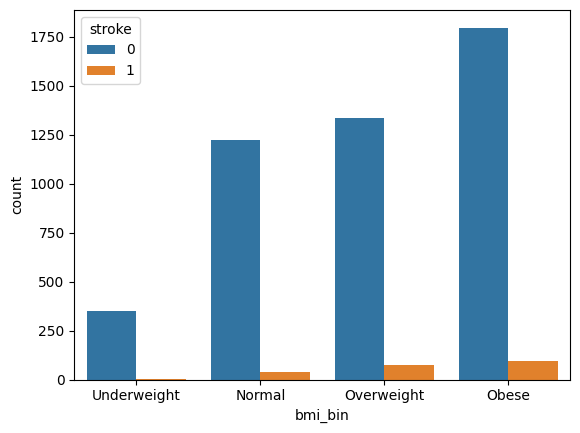

In [481]:
# bmi

bmi_bins = [0, 18.5, 25, 30, np.inf]
bmi_labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
df["bmi_bin"] = pd.cut(df["bmi"], bins= bmi_bins, labels= bmi_labels, right="False")

sns.countplot(data = df, x = "bmi_bin", hue="stroke")
plt.show()


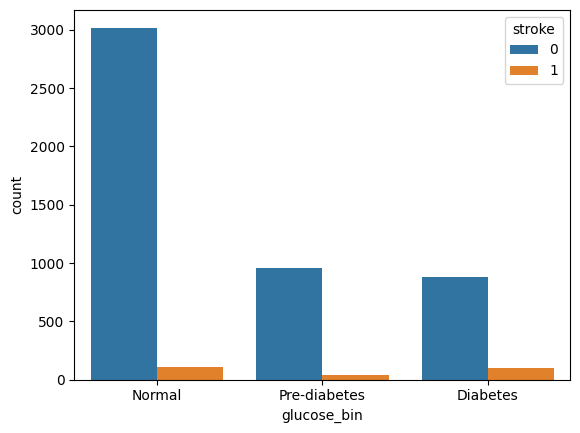

In [482]:
# avg_glucose_level

glucose_bins = [0, 100, 126, np.inf]
glucose_labels = ["Normal", "Pre-diabetes", "Diabetes"]
df["glucose_bin"] = pd.cut(df["avg_glucose_level"], bins=glucose_bins, labels= glucose_labels, right=False)

sns.countplot(data= df, x="glucose_bin", hue="stroke", order=glucose_labels)
plt.show()

Multivariate analysis

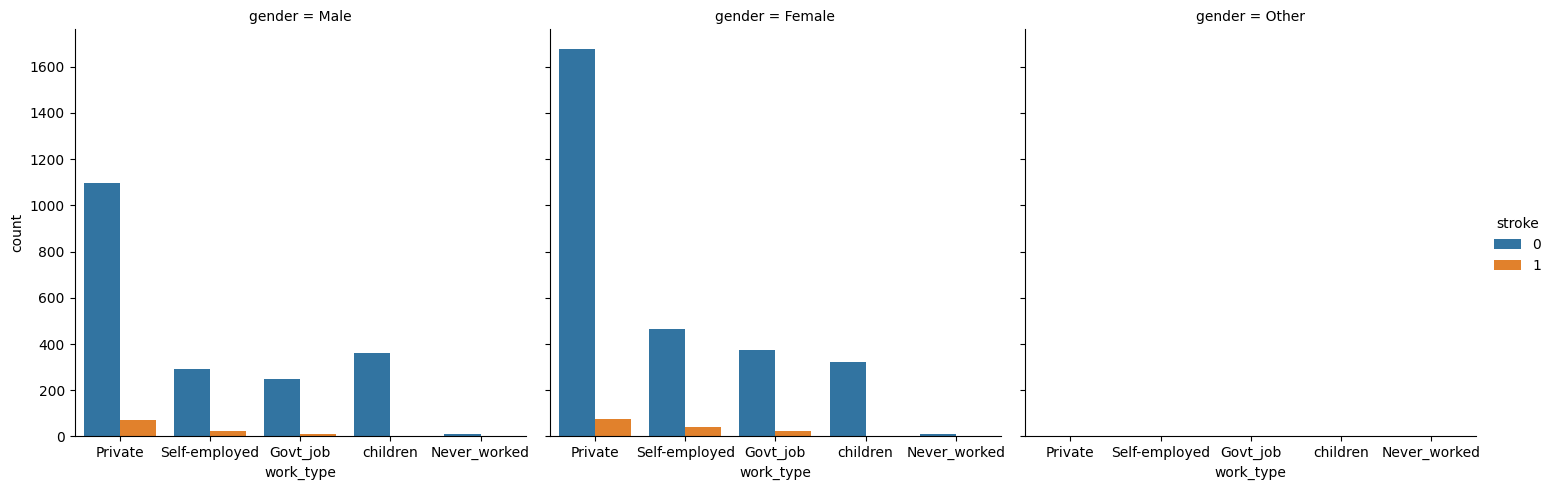

In [483]:
sns.catplot(data= df, x="work_type", hue="stroke" , col="gender",kind= "count")
plt.show()

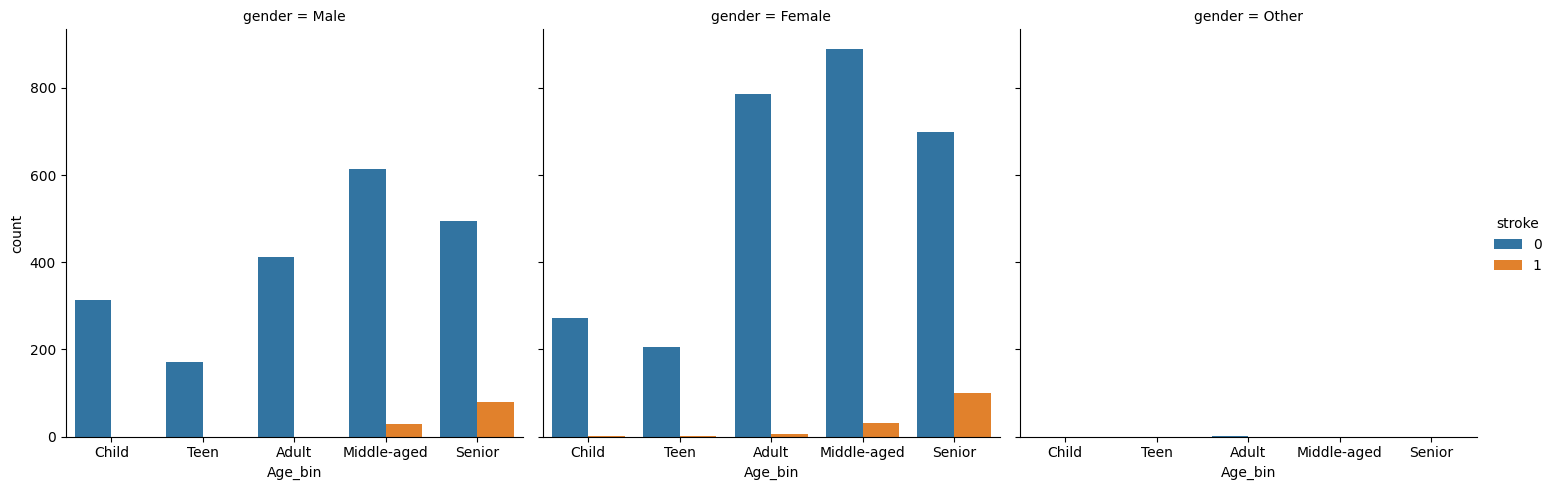

In [484]:
sns.catplot(data = df, x="Age_bin", hue="stroke", col="gender", kind="count")
plt.show()

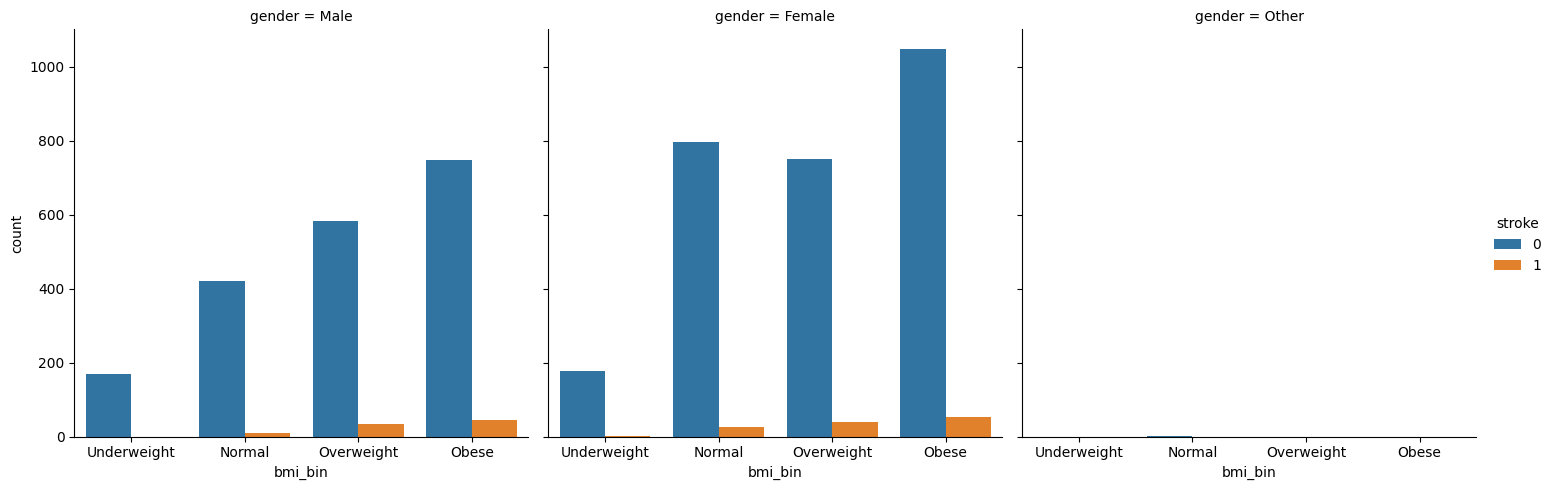

In [485]:
sns.catplot(data = df, x="bmi_bin", hue="stroke", col="gender", kind="count")
plt.show()

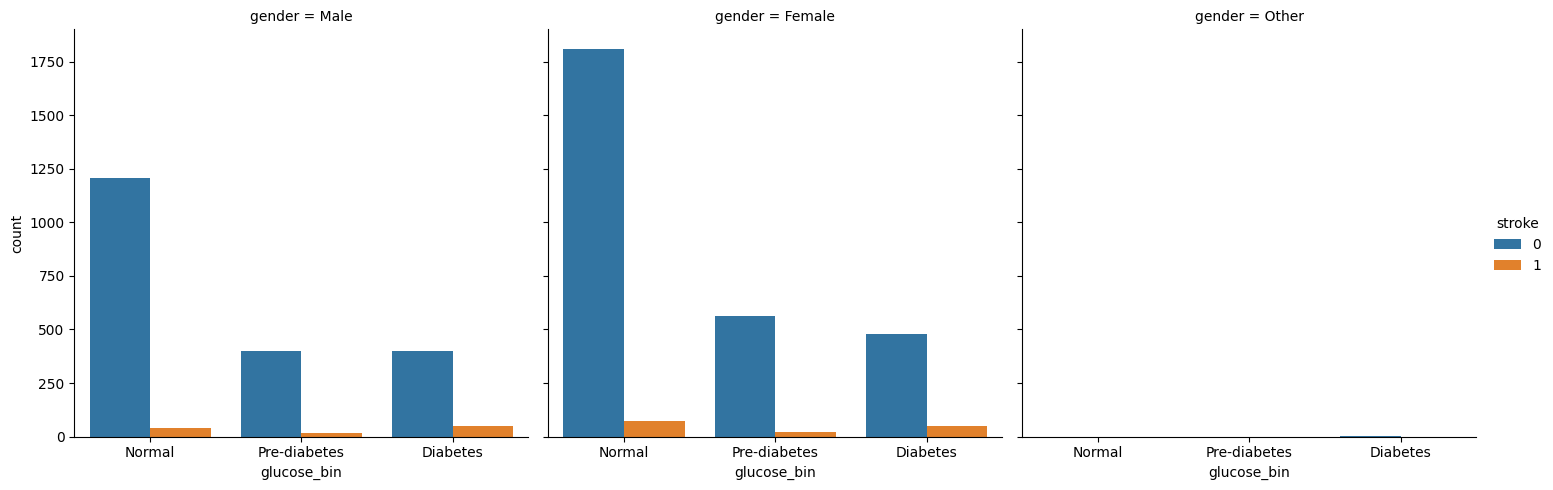

In [486]:
sns.catplot(data = df, x="glucose_bin", hue="stroke", col="gender", kind="count")
plt.show()

Correlation

<Axes: >

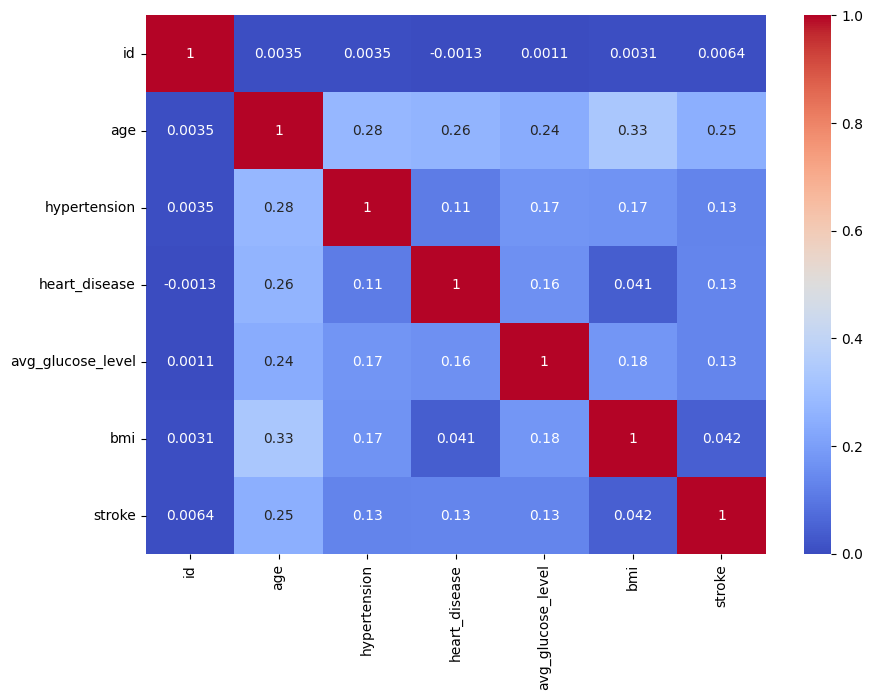

In [487]:
numeric = df.select_dtypes(include= np.number)

plt.figure(figsize=(10,7))
sns.heatmap(numeric.corr(), annot = True, cmap="coolwarm")

Modelling and machine learning

In [488]:
df = df.drop(columns=["id", "Age_bin", "bmi_bin", "glucose_bin"], errors="ignore")

In [489]:
# preparing data for modelling

df["bmi"] = df["bmi"].fillna(df["bmi"].median())
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [490]:
X = df.drop(columns="stroke")
Y = df["stroke"]

In [491]:
X.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked


In [492]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   str    
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   str    
 5   work_type          5110 non-null   str    
 6   Residence_type     5110 non-null   str    
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   str    
dtypes: float64(3), int64(2), str(5)
memory usage: 554.8 KB


In [493]:
   X = pd.get_dummies(X, drop_first=True, dtype=int)
   X.head()


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,0,1,0,1,0,0,1,1,0,0
1,61.0,0,0,202.21,28.1,0,0,1,0,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,0,1,0,1,0,0,0,0,1,0
3,49.0,0,0,171.23,34.4,0,0,1,0,1,0,0,1,0,0,1
4,79.0,1,0,174.12,24.0,0,0,1,0,0,1,0,0,0,1,0


In [494]:
# splitting the data into train and test

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size= 0.2 , random_state= 42, stratify= Y)

In [495]:
# Training model

from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)

model.fit(X_train, Y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [496]:
y_pred = model.predict(
    X_test
)

In [497]:
y_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

Model evaluation

In [498]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(Y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9521


In [499]:
from sklearn.metrics import classification_report

print(
    classification_report(
        Y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



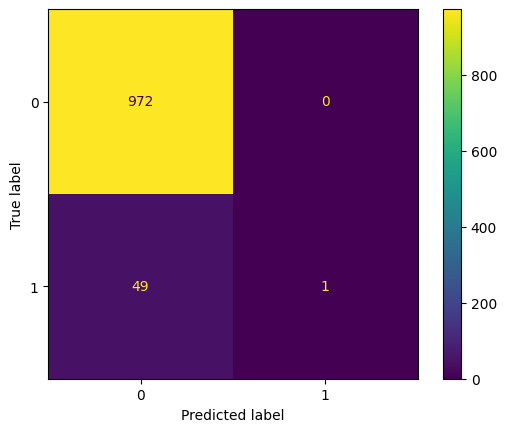

In [500]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(Y_test,y_pred)
plt.show()